# Canadian day-ahead demand forecasting

Run this notebook from the repository root using the project’s Python kernel. It audits HFED data, trains the residual STGCN, local residual XGBoost, and PBC models, and compares them with the original baselines on the same observed test hours. Checkpoints go under `models/` and the dashboard and API read the published forecasts and metrics from `results/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import yaml
from IPython.display import display
from joblib import dump
from xgboost import XGBRegressor

from src.data.holiday_client import get_holiday_df_for_data_range
from src.data.pipeline import RegionalStandardScaler, run_pipeline
from src.evaluation.evaluator import compute_peak_thresholds, run_full_evaluation
from src.evaluation.metrics import pinball_loss
from src.high_demand.detector import flag_high_demand
from src.models.pbc.demand import PROBABILITIES, DemandPBC
from src.models.stgnn.graph_builder import build_all_graphs
from src.models.stgnn.residual import (
    KEY,
    TIMEZONES,
    ResidualSTGCN,
    build_examples,
    fit_graph,
    predict_graph,
)

config = yaml.safe_load(Path("config/config.yaml").read_text(encoding="utf-8"))
paths = config["paths"]
processed = Path(paths["processed_data_dir"])
models_dir = Path(paths["model_dir"])
results_dir = Path(paths["results_dir"])
graph_dir = models_dir / "stgnn"
local_dir = models_dir / "xgboost"
pbc_dir = models_dir / "pbc"
for directory in (graph_dir, local_dir, pbc_dir, results_dir):
    directory.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)
sns.set_theme(style="whitegrid")
print(f"PyTorch {torch.__version__} on {device}")

PyTorch 2.6.0+cu124 on cuda


## Prepare data and baselines

Run all cells to publish the new experiment. Enable `REBUILD_DATA` to regenerate the processed files and `RETRAIN_BASELINES` to refit the original baselines. Otherwise the notebook uses the processed data and saved baseline predictions. Set `RETRAIN_NEW_MODELS` to `False` to reuse compatible residual checkpoints and regenerate the evaluation and PBC.

In [2]:
REBUILD_DATA = False
RETRAIN_BASELINES = False
RETRAIN_NEW_MODELS = True
if REBUILD_DATA or not all((processed / f"{name}.parquet").exists() for name in ("train", "val", "test")):
    run_pipeline(config)

splits = {name: pd.read_parquet(processed / f"{name}.parquet") for name in ("train", "val", "test")}
train = splits["train"]
data = pd.concat(splits.values(), ignore_index=True)
regions = sorted(train["region"].unique())
holiday_path = Path(paths["holiday_cache_dir"]) / "holidays_df.parquet"
if REBUILD_DATA or not holiday_path.exists():
    years = data["time_utc"].dt.year
    holiday_path.parent.mkdir(parents=True, exist_ok=True)
    holidays = get_holiday_df_for_data_range(
        int(years.min()), int(years.max()), hfed_regions=regions,
        cache_path=config["holidays"]["cache_file"],
    )
    holidays.to_parquet(holiday_path, index=False)
assert not data.duplicated(["region", "time_utc"]).any()
for earlier, later in [("train", "val"), ("val", "test")]:
    assert splits[earlier]["time_utc"].max() < splits[later]["time_utc"].min()
display(pd.DataFrame({name: {
    "rows": len(frame), "start UTC": frame["time_utc"].min(), "end UTC": frame["time_utc"].max(),
} for name, frame in splits.items()}).T)

baseline_names = ("naive_day", "naive_week", "xgboost", "lstm", "gru")
if RETRAIN_BASELINES or not all((results_dir / f"predictions_{name}.parquet").exists() for name in baseline_names):
    from src.models.gru_model import GRUForecaster
    from src.models.lstm_model import LSTMForecaster
    from src.models.naive import run_naive_baselines
    from src.models.xgboost_model import XGBoostForecaster

    validation, test = splits["val"], splits["test"]
    baseline_forecasts = run_naive_baselines(pd.concat([train, validation]), test, regions)
    boosted = XGBoostForecaster(config)
    boosted.fit(train, validation, model_dir=models_dir)
    baseline_forecasts["xgboost"] = boosted.predict(test)

    scaler = RegionalStandardScaler.from_dict(
        json.loads((processed / "scaler_stats.json").read_text(encoding="utf-8"))
    )
    scale_columns = [column for column in train.columns if column in scaler.stats[regions[0]]]
    scaled_train, scaled_validation, scaled_test = (
        scaler.transform(part, feature_cols=scale_columns) for part in (train, validation, test)
    )
    for forecaster in (LSTMForecaster(config), GRUForecaster(config)):
        forecaster.fit(scaled_train, scaled_validation, model_dir=models_dir)
        forecast = forecaster.predict(scaled_test)
        for region, rows in forecast.groupby("region").groups.items():
            for column in ("predicted", "actual"):
                forecast.loc[rows, column] = scaler.inverse_transform_demand(
                    forecast.loc[rows, column].to_numpy(), region
                )
        baseline_forecasts[forecaster.name] = forecast

    for name, forecast in baseline_forecasts.items():
        forecast.to_parquet(results_dir / f"predictions_{name}.parquet", index=False)

# The original naive files are keyed by UTC. Publish the local date and hour
# expected by the same dashboard and API routes as the other models.
for name in ("naive_day", "naive_week"):
    path = results_dir / f"predictions_{name}.parquet"
    forecast = pd.read_parquet(path)
    if "forecast_date" not in forecast.columns:
        parts = []
        for region, regional in forecast.groupby("region", sort=False):
            local = pd.to_datetime(regional["time_utc"], utc=True).dt.tz_convert(TIMEZONES[region])
            parts.append(regional.assign(forecast_date=local.dt.date, target_hour=local.dt.hour))
        pd.concat(parts, ignore_index=True).to_parquet(path, index=False)

,rows,start UTC,end UTC
train,254659,2019-01-01 00:00:00,2023-12-31 23:00:00
val,34944,2024-01-01 00:00:00,2024-06-30 23:00:00
test,32269,2024-07-01 00:00:00,2024-12-31 23:00:00


## Data audit

Coverage uses a full regional UTC grid, so a province that started collecting data later is visible as missing. Profile and correlation plots use training observations. Demand is normalized within each province for the profile comparison.

,start_utc,end_utc,observed_hours,median_mw,full_grid_coverage_pct
region,,,,,
AB,2023-02-07 15:00:00,2024-11-18 17:00:00,14711,9885.25,27.96
BC,2019-01-01 00:00:00,2024-12-31 23:00:00,52607,7278.00,100.00
NB,2019-01-01 00:00:00,2024-12-31 23:00:00,52525,1545.36,99.84
NL,2022-09-13 19:00:00,2024-12-31 23:00:00,18589,889.00,35.33
NS,2022-02-20 14:00:00,2024-10-08 18:00:00,21362,1222.87,40.61
ON,2019-01-01 00:00:00,2024-12-31 23:00:00,52608,15372.50,100.00
PE,2019-01-01 00:00:00,2024-12-31 23:00:00,50619,180.70,96.22
QC,2019-01-01 05:00:00,2024-12-31 23:00:00,52572,19864.28,99.93


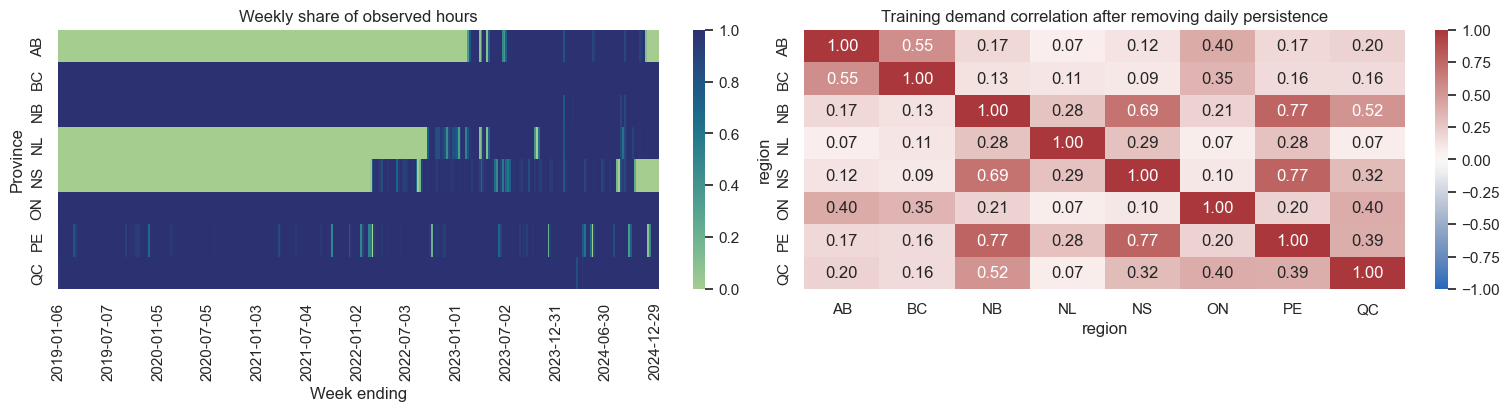

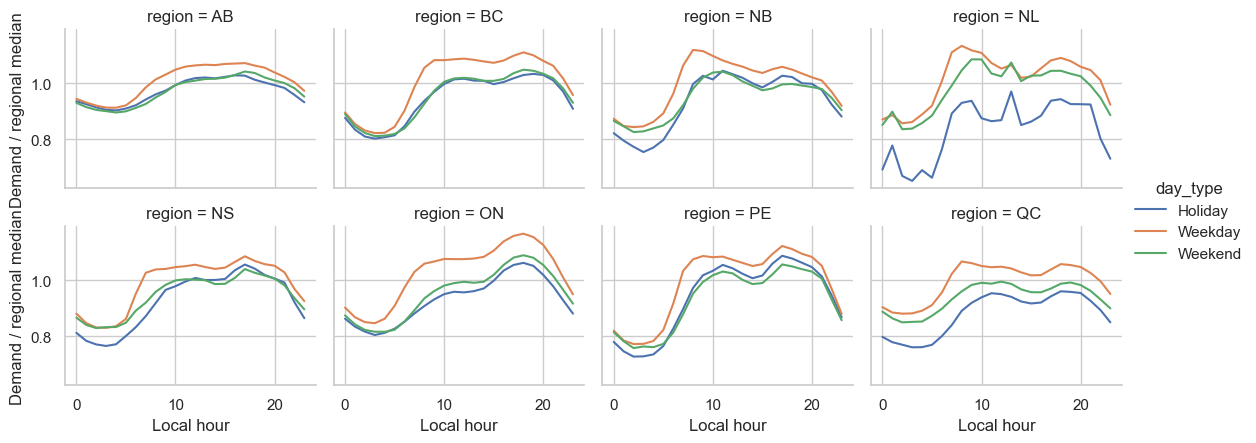

In [3]:
wide = data.pivot(index="time_utc", columns="region", values="demand_mw").asfreq("h")
audit = data.groupby("region").agg(
    start_utc=("time_utc", "min"), end_utc=("time_utc", "max"),
    observed_hours=("demand_mw", "count"), median_mw=("demand_mw", "median"),
)
audit["full_grid_coverage_pct"] = 100 * wide.notna().mean()
display(audit.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4), layout="constrained")
weekly = wide.notna().resample("W").mean().T
weekly.columns = weekly.columns.strftime("%Y-%m-%d")
sns.heatmap(weekly, vmin=0, vmax=1, cmap="crest", xticklabels=26, ax=axes[0])
axes[0].set(title="Weekly share of observed hours", xlabel="Week ending", ylabel="Province")
train_wide = train.pivot(index="time_utc", columns="region", values="demand_mw").asfreq("h")
sns.heatmap(train_wide.diff(24).corr(), vmin=-1, vmax=1, center=0, cmap="vlag", annot=True,
            fmt=".2f", ax=axes[1])
axes[1].set(title="Training demand correlation after removing daily persistence")
plt.show()

profile = train.dropna(subset=["demand_mw"]).copy()
profile["relative_demand"] = profile["demand_mw"] / profile.groupby("region")["demand_mw"].transform("median")
profile["local_hour"] = pd.to_datetime(profile["time_local"]).dt.hour
profile["day_type"] = np.where(profile["is_holiday"].eq(1), "Holiday",
                               np.where(profile["is_weekend"].eq(1), "Weekend", "Weekday"))
hourly = profile.groupby(["region", "day_type", "local_hour"])["relative_demand"].median().reset_index()
chart = sns.relplot(hourly, x="local_hour", y="relative_demand", hue="day_type", col="region",
                    col_wrap=4, kind="line", height=2.3, aspect=1.25)
chart.set_axis_labels("Local hour", "Demand / regional median")
plt.show()

## Residual STGCN and graph ablation

The model starts from a recent observed same-hour demand value and learns a residual. Temporal convolutions encode each node’s recent history. A graph convolution combines neighboring states with availability masks, and the decoder uses the province, target calendar, and seven seasonal lags. Missing labels are masked in the training loss. The four graph types share architecture and seeds. The identity graph tests whether spatial sharing helps.

Examples use a province’s own 23:00 issue time and UTC-aligned graph history. Newfoundland targets use the HFED UTC hourly slots labeled by local hour, so their local timestamps occur on the half hour. Local DST transition days lack a unique 24-slot mapping and are excluded. Model fitting uses 2019–2023, early stopping uses January–March 2024, model selection uses April, and PBC fits on May–June. Boundary days are held out so that targets from one stage cannot overlap the next stage’s issue times.

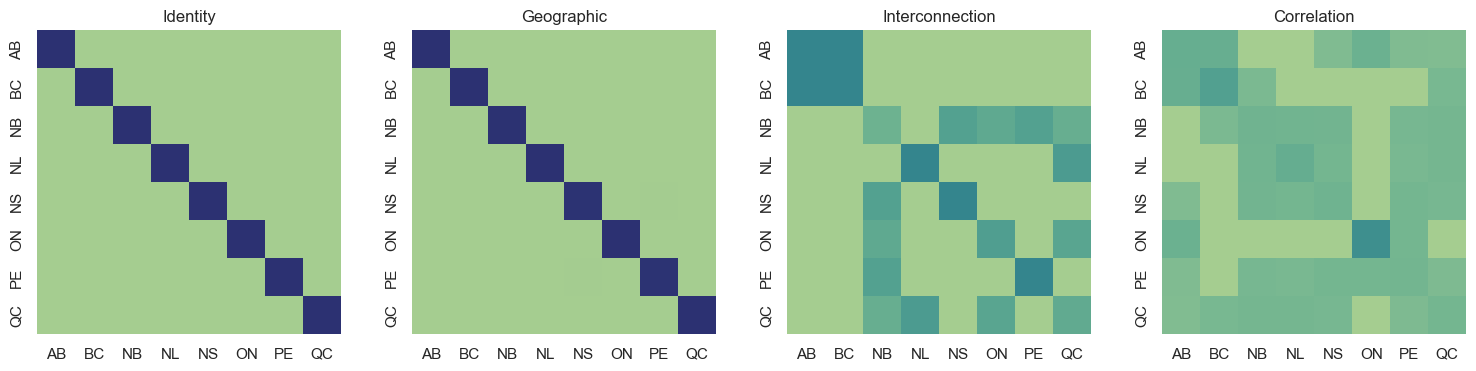

Forecasts ready for identity graph (2 seeds)


Forecasts ready for geographic graph (2 seeds)


Forecasts ready for interconnection graph (2 seeds)


Forecasts ready for correlation graph (2 seeds)


,April MAE (MW)
residual_stgcn_interconnection,215.999031
residual_stgcn_identity,217.959962
residual_stgcn_geographic,217.962257
residual_stgcn_correlation,218.824293


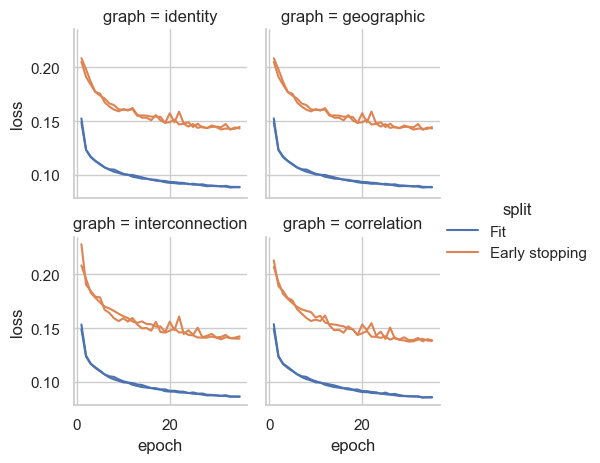

In [4]:
frame, tensors, scaling = build_examples(data, train, regions)
issue_dates = frame["forecast_date"].iloc[::24].reset_index(drop=True)
fit_mask = issue_dates.lt("2023-12-30").to_numpy()
early_mask = issue_dates.between("2024-01-03", "2024-03-30").to_numpy()
select_mask = issue_dates.between("2024-04-02", "2024-04-29").to_numpy()
calibration_mask = issue_dates.between("2024-05-02", "2024-06-29").to_numpy()
test_mask = issue_dates.between("2024-07-01", "2024-12-30").to_numpy()
graphs = build_all_graphs(regions, train, config["stgnn"]["geographic_max_distance_km"],
                          config["stgnn"]["correlation_threshold"])

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), layout="constrained")
for axis, (name, adjacency) in zip(axes, graphs.items()):
    sns.heatmap(adjacency, vmin=0, vmax=1, cmap="crest", xticklabels=regions,
                yticklabels=regions, square=True, cbar=False, ax=axis)
    axis.set_title(name.title())
plt.show()

scored = select_mask | calibration_mask | test_mask
graph_forecasts = {}
histories = []
for name, adjacency in graphs.items():
    members = []
    for seed in (42, 123):
        checkpoint = graph_dir / f"residual_stgcn_{name}_{seed}.pt"
        history_path = graph_dir / f"history_residual_{name}_seed{seed}.json"
        if RETRAIN_NEW_MODELS or not checkpoint.exists():
            model, history = fit_graph(adjacency, tensors, fit_mask, early_mask, device, seed)
            torch.save({key: value.cpu() for key, value in model.state_dict().items()}, checkpoint)
            history_path.write_text(json.dumps(history), encoding="utf-8")
        else:
            model = ResidualSTGCN(adjacency, tensors[1].shape[-1]).to(device)
            model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
            history = json.loads(history_path.read_text(encoding="utf-8")) if history_path.exists() else []
        members.append(predict_graph(model, frame, tensors, scaling, scored))
        if history:
            histories.append(pd.DataFrame(history, columns=["Fit", "Early stopping"])
                             .assign(graph=name, seed=seed, epoch=np.arange(len(history)) + 1))
    forecast = members[0].copy()
    forecast["predicted"] = np.mean([member["predicted"] for member in members], axis=0)
    graph_forecasts[f"residual_stgcn_{name}"] = forecast
    print(f"Forecasts ready for {name} graph ({len(members)} seeds)", flush=True)

selection = pd.Series({
    name: (forecast.loc[forecast["forecast_date"].dt.month.eq(4), "predicted"]
           - forecast.loc[forecast["forecast_date"].dt.month.eq(4), "actual"]).abs().mean()
    for name, forecast in graph_forecasts.items()
}, name="April MAE (MW)").sort_values()
best_graph = selection.index[0]
display(selection.to_frame())

if histories:
    curves = pd.concat(histories).melt(id_vars=["graph", "seed", "epoch"], var_name="split", value_name="loss")
    sns.relplot(curves, x="epoch", y="loss", hue="split", col="graph", units="seed",
                estimator=None, kind="line", col_wrap=2, height=2.4)
    plt.show()

## Graph and local residual ensemble

A separate local XGBoost model learns from the same available lags, issue-time history, and calendar. The ensemble chooses a graph/local weight per province on April MAE. Candidate weights retain at least 25% graph contribution. This hybrid is reported separately from the pure graph models.

In [5]:
history, calendar, anchors, nodes, targets = (tensor.numpy() for tensor in tensors)
local = frame.loc[np.repeat(scored, 24)].reset_index(drop=True).copy()
local["predicted"] = np.nan
for node, region in enumerate(regions):
    region_samples = nodes == node
    sample_history = history[region_samples, :, node, :].reshape(region_samples.sum(), -1)
    features = np.concatenate([
        calendar[region_samples], np.repeat(sample_history[:, None, :], 24, axis=1),
    ], axis=-1)
    train_rows = fit_mask[region_samples, None] & np.isfinite(targets[region_samples])
    residual = targets[region_samples] - anchors[region_samples]
    regressor = XGBRegressor(n_estimators=240, max_depth=4, learning_rate=0.04,
                             subsample=0.85, colsample_bytree=0.8, n_jobs=4,
                             tree_method="hist", random_state=42)
    checkpoint = local_dir / f"local_residual_{region}.json"
    if RETRAIN_NEW_MODELS or not checkpoint.exists():
        regressor.fit(features[train_rows], residual[train_rows])
        regressor.save_model(checkpoint)
    else:
        regressor.load_model(checkpoint)
    candidates = scored[region_samples]
    selected_features = features[candidates]
    corrected = anchors[region_samples][candidates] + regressor.predict(
        selected_features.reshape(-1, selected_features.shape[-1])
    ).reshape(-1, 24)
    local.loc[local["region"].eq(region), "predicted"] = (
        corrected.ravel() * scaling.loc[region, "std"] + scaling.loc[region, "mean"]
    ).clip(min=0)

hybrid = graph_forecasts[best_graph].copy()
weights = {}
for region in regions:
    region_rows = hybrid["region"].eq(region)
    april = region_rows & hybrid["forecast_date"].dt.month.eq(4)
    graph_point = hybrid.loc[april, "predicted"]
    local_point = local.loc[april, "predicted"]
    truth = hybrid.loc[april, "actual"]
    weights[region] = min((0.25, 0.50, 0.75, 1.0), key=lambda w: (
        w * graph_point + (1 - w) * local_point - truth
    ).abs().mean())
    weight = weights[region]
    hybrid.loc[region_rows, "predicted"] = (
        weight * hybrid.loc[region_rows, "predicted"] + (1 - weight) * local.loc[region_rows, "predicted"]
    )
display(pd.Series(weights, name="April-selected graph weight").to_frame())
(graph_dir / "residual_metadata.json").write_text(json.dumps({
    "regions": regions, "scaling": scaling.to_dict(orient="index"),
    "selected_graph": best_graph, "hybrid_graph_weights": weights,
}, indent=2), encoding="utf-8")

,April-selected graph weight
AB,0.75
BC,1.00
NB,1.00
NL,1.00
NS,1.00
ON,1.00
PE,1.00
QC,1.00


996

## PBC model

This demand adaptation follows Mouatadid et al., [*Advancing subseasonal forecasting with machine learning*](https://doi.org/10.1038/s41586-026-11126-x). An empirical residual CDF represents the base forecast uncertainty. Debias++ learns calendar-dependent adjustments and Persistence++ uses recent observed forecast errors. The branches are projected with isotonic regression and averaged on a common threshold grid. The median is the point forecast. During test evaluation the history can update only after an hourly observation is available. No test labels are used to fit the regressions.

In [6]:
thresholds = compute_peak_thresholds(train, regions, config["high_demand"]["threshold_percentile"])
april = hybrid["forecast_date"].dt.month.eq(4)
graph_base = graph_forecasts[best_graph]
base_name, base = min(
    [(best_graph, graph_base), ("stgcn_local_hybrid", hybrid)],
    key=lambda candidate: (candidate[1].loc[april, "predicted"] - candidate[1].loc[april, "actual"]).abs().mean(),
)
calibration = base.loc[base["forecast_date"].between("2024-05-02", "2024-06-29")]
held_out = base.loc[base["forecast_date"].between("2024-07-01", "2024-12-30")]
assert calibration["target_at"].max() + pd.Timedelta(hours=1) <= held_out["issued_at"].min()
calibrator = DemandPBC().fit(calibration)
pbc = calibrator.predict(held_out, thresholds)
q_cols = [f"q{q * 100:02.0f}" for q in PROBABILITIES]
assert np.all(np.diff(pbc[q_cols], axis=1) >= 0)
assert pbc["prob_exceed_threshold"].between(0, 1).all()
print("PBC base selected on April:", base_name)
dump(calibrator, pbc_dir / "model.joblib", compress=3)
(pbc_dir / "meta.json").write_text(json.dumps({"base_model": base_name}, indent=2), encoding="utf-8")
pbc.to_parquet(results_dir / "probabilistic_predictions.parquet", index=False)

PBC base selected on April: stgcn_local_hybrid


## Held-out comparison

All models are scored on observed province/date/hour keys that they share. A key must also have matching saved and rebuilt demand within 0.1 MW for each baseline. This guards against clock or data-version differences, notably in Newfoundland and PEI. The comparison is for this matched subset, so the historical handoff's aggregate scores are not directly comparable.

,Available observed test keys,Saved actual within 0.1 MW
naive_day,30669,1.000
naive_week,30199,1.000
xgboost,30797,0.920
lstm,29402,0.916
gru,29402,0.916
residual_stgcn_identity,30923,1.000
residual_stgcn_geographic,30923,1.000
residual_stgcn_interconnection,30923,1.000
residual_stgcn_correlation,30923,1.000
local_residual_xgboost,30923,1.000


Shared forecast keys: 28,545; matched observations: 26,221


,mae,rmse,mape,mape_n_excluded,n_obs,peak_mae,peak_rmse
model,,,,,,,
residual_stgcn_geographic,202.825,428.436,2.681,0,26221,434.622,730.620
residual_stgcn_identity,202.826,428.429,2.682,0,26221,434.411,730.192
residual_stgcn_interconnection,205.468,432.417,2.663,0,26221,460.889,771.328
stgcn_local_hybrid,205.807,432.651,2.666,0,26221,463.716,772.581
residual_stgcn_correlation,206.478,431.482,2.710,0,26221,437.549,735.564
pbc,207.163,433.772,2.653,0,26221,453.167,760.808
gru,230.094,441.874,2.898,0,26221,621.295,953.429
local_residual_xgboost,241.338,481.471,3.095,0,26221,575.290,901.040
lstm,255.884,475.509,3.170,0,26221,598.663,982.823


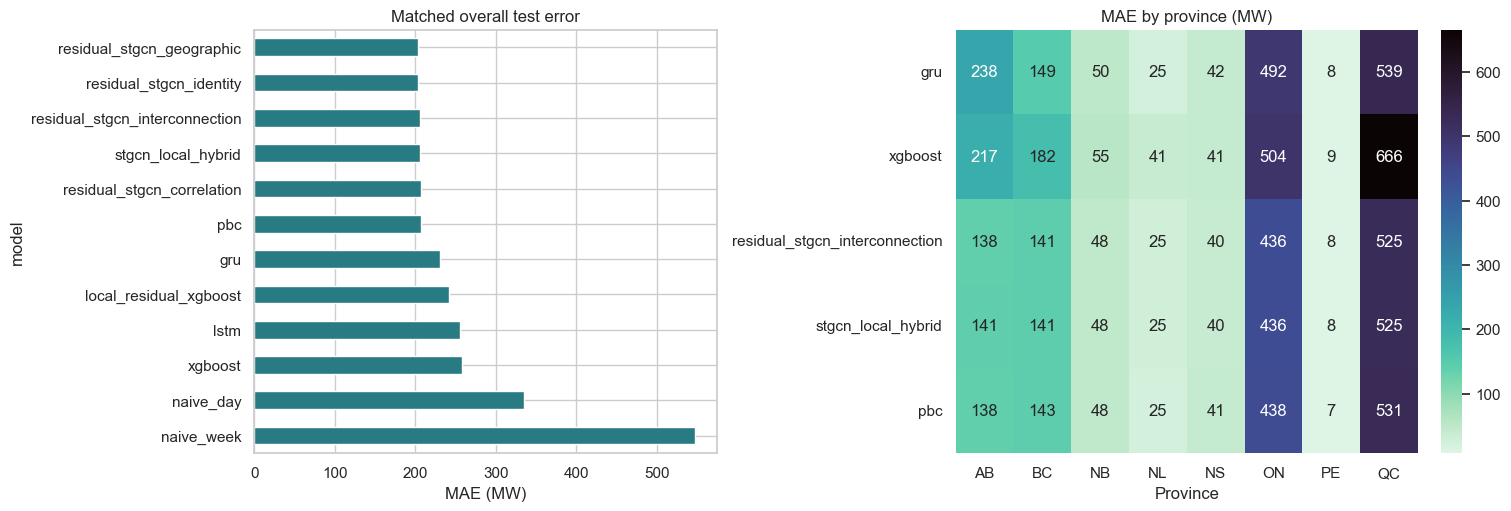

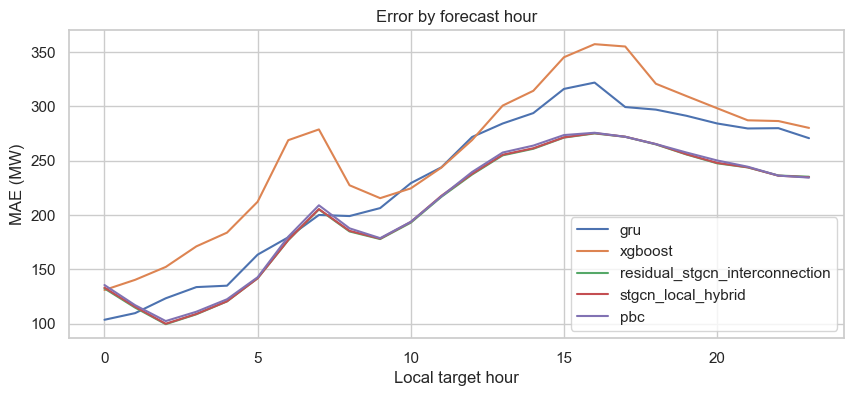

In [7]:
saved = {name: pd.read_parquet(results_dir / f"predictions_{name}.parquet") for name in baseline_names}
candidates = dict(saved, **graph_forecasts, local_residual_xgboost=local,
                  stgcn_local_hybrid=hybrid, pbc=pbc)
actual = held_out.dropna(subset=["actual"]).set_index(KEY)["actual"].sort_index()
comparison = actual.to_frame()
coverage = {}
actual_agreement = {}
comparable = pd.Series(True, index=actual.index)
for name, forecast in candidates.items():
    if name in ("naive_day", "naive_week"):
        # Naive forecasts are keyed by the observed UTC timestamp.
        lookup = held_out[[*KEY, "target_at"]]
        forecast = forecast[["region", "time_utc", "predicted", "actual"]].merge(
            lookup, left_on=["region", "time_utc"], right_on=["region", "target_at"],
            validate="one_to_one",
        )
    forecast = forecast.assign(forecast_date=pd.to_datetime(forecast["forecast_date"]))
    aligned = forecast.drop_duplicates(KEY).set_index(KEY).reindex(actual.index)
    comparison[name] = aligned["predicted"]
    coverage[name] = aligned["predicted"].notna().sum()
    with_actual = aligned["actual"].notna()
    agrees = np.isclose(aligned["actual"], actual, rtol=0, atol=0.1)
    actual_agreement[name] = agrees[with_actual].mean()
    if name in baseline_names:
        comparable &= agrees
common_keys = comparison.dropna()
common = common_keys.loc[comparable.reindex(common_keys.index)]
assert len(common) > 0
display(pd.DataFrame({"Available observed test keys": coverage,
                      "Saved actual within 0.1 MW": actual_agreement}).round(3))
print(f"Shared forecast keys: {len(common_keys):,}; matched observations: {len(common):,}")
for name, forecast in candidates.items():
    if name not in baseline_names:
        test_forecast = forecast[forecast["forecast_date"].between("2024-07-01", "2024-12-30")]
        test_forecast.to_parquet(results_dir / f"predictions_{name}.parquet", index=False)

matched = common.reset_index()
holiday_lookup = held_out[[*KEY, "target_at"]].merge(
    splits["test"][["region", "time_utc", "is_holiday"]],
    left_on=["region", "target_at"], right_on=["region", "time_utc"],
    how="left", validate="one_to_one",
).set_index(KEY)["is_holiday"]
matched["is_holiday"] = holiday_lookup.reindex(common.index).fillna(0).to_numpy()
evaluation_inputs = {
    name: matched[[*KEY, "actual", "is_holiday", name]].rename(columns={name: "predicted"})
    for name in candidates
}
_, comparison_table = run_full_evaluation(evaluation_inputs, train, regions, config, results_dir)
metrics = comparison_table.set_index("model")
display(metrics.round(3))

absolute = common.drop(columns="actual").sub(common["actual"], axis=0).abs()
fig, axes = plt.subplots(1, 2, figsize=(15, 5), layout="constrained")
metrics["mae"].sort_values().plot.barh(ax=axes[0], color="#287b82")
axes[0].invert_yaxis()
axes[0].set(xlabel="MAE (MW)", title="Matched overall test error")
selected = list(dict.fromkeys(["gru", "xgboost", best_graph, "stgcn_local_hybrid", "pbc"]))
sns.heatmap(absolute[selected].groupby(level="region").mean().T, annot=True, fmt=".0f",
            cmap="mako_r", ax=axes[1])
axes[1].set(title="MAE by province (MW)", xlabel="Province", ylabel="")
plt.show()
absolute[selected].groupby(level="target_hour").mean().plot(figsize=(10, 4),
    xlabel="Local target hour", ylabel="MAE (MW)", title="Error by forecast hour")
plt.show()

## Calibration and high-demand performance

CRPS compares the PBC distribution to the uncorrected empirical residual CDF on identical cases. Pinball loss measures quantile accuracy, and the coverage plot compares nominal intervals with observed coverage. Peak thresholds are estimated from training data by province.

,Matched test
PBC CRPS (MW),156.276138
Empirical CDF CRPS (MW),156.537442
Mean pinball loss (MW),66.445630
80% interval coverage,0.750810
Mean 80% interval width (MW),593.364673


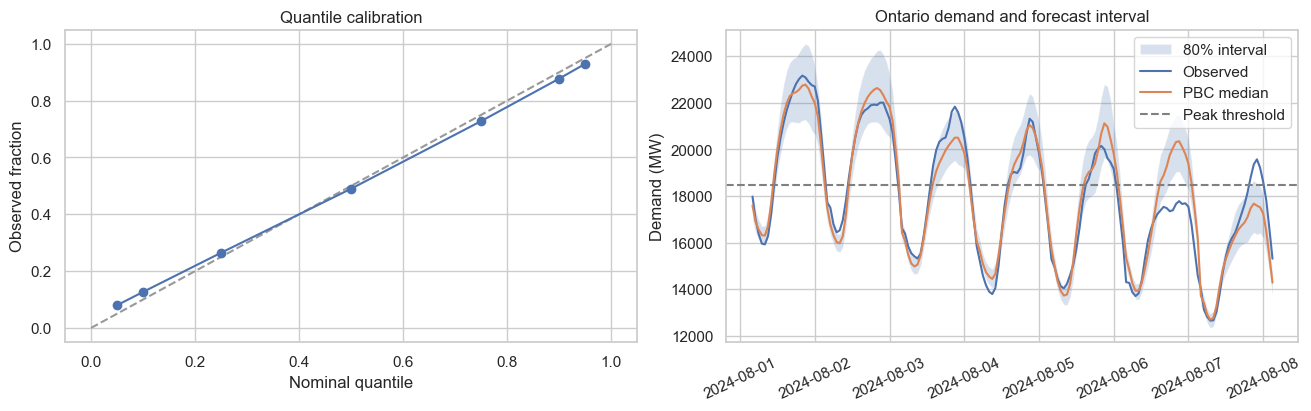

,Peak-hour MAE (MW)
residual_stgcn_identity,434.410923
residual_stgcn_geographic,434.622420
residual_stgcn_correlation,437.549435
pbc,453.167272
residual_stgcn_interconnection,460.888563
stgcn_local_hybrid,463.716446
local_residual_xgboost,575.290131
lstm,598.663256
gru,621.295444
naive_day,661.716765


,flagged_hours,flagged_share
region,,
AB,391,0.116369
BC,485,0.111035
NB,226,0.051740
NL,19,0.004448
NS,0,0.000000
ON,788,0.180403
PE,450,0.112952
QC,265,0.060668


In [8]:
matched_pbc = pbc.set_index(KEY).reindex(common.index)
truth = matched_pbc["actual"].to_numpy()
probability_scores = {
    "PBC CRPS (MW)": matched_pbc["crps_pbc"].mean(),
    "Empirical CDF CRPS (MW)": matched_pbc["crps_empirical"].mean(),
    "Mean pinball loss (MW)": np.mean([
        pinball_loss(truth, matched_pbc[column].to_numpy(), q) for column, q in zip(q_cols, PROBABILITIES)
    ]),
    "80% interval coverage": matched_pbc["actual"].between(matched_pbc["q10"], matched_pbc["q90"]).mean(),
    "Mean 80% interval width (MW)": (matched_pbc["q90"] - matched_pbc["q10"]).mean(),
}
display(pd.Series(probability_scores).to_frame("Matched test"))
pbc_metrics_path = results_dir / "metrics_pbc.json"
pbc_metrics = json.loads(pbc_metrics_path.read_text(encoding="utf-8"))
pbc_metrics["probabilistic"] = probability_scores
pbc_metrics_path.write_text(json.dumps(pbc_metrics, indent=2), encoding="utf-8")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="0.6")
axes[0].plot(PROBABILITIES, (truth[:, None] <= matched_pbc[q_cols].to_numpy()).mean(axis=0), marker="o")
axes[0].set(xlabel="Nominal quantile", ylabel="Observed fraction", title="Quantile calibration")
region = "ON"
week = pbc.loc[pbc["region"].eq(region) & pbc["forecast_date"].between("2024-08-01", "2024-08-07")]
week = week.sort_values("target_at")
axes[1].fill_between(week["target_at"], week["q10"], week["q90"], alpha=0.22, label="80% interval")
axes[1].plot(week["target_at"], week["actual"], label="Observed")
axes[1].plot(week["target_at"], week["predicted"], label="PBC median")
axes[1].axhline(thresholds[region], color="0.5", linestyle="--", label="Peak threshold")
axes[1].set(title="Ontario demand and forecast interval", ylabel="Demand (MW)")
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend()
plt.show()

flags = flag_high_demand(pbc, thresholds, prob_col="prob_exceed_threshold")
flags.to_parquet(results_dir / "high_demand_flags.parquet", index=False)
peak = common["actual"].ge(common.index.get_level_values("region").map(thresholds))
display(absolute.loc[peak].mean().sort_values().rename("Peak-hour MAE (MW)").to_frame())
display(flags.groupby("region")["is_high_demand"].agg(["sum", "mean"]).rename(
    columns={"sum": "flagged_hours", "mean": "flagged_share"}
))